# ms00 阶段 0：准备（队列、开发/测试划分、逐视频记录、身份错配检查）

整套 ms00–ms04 照 O'Shaughnessy et al., *Dynamics of Dominance in Interacting Zebrafish*, PRX Life **2**, 043006 (2024) 的流程：
每对鱼一个状态 (D, θ_a, θ_b) → 分格 → τ 间隔转移矩阵 → Infomap 聚类。参数选择的规则写在各 notebook 里；
**用到行为标记的步骤只在开发组做，测试组留到 ms04 最后一格 `FINAL=True` 才打开。**

| notebook | 阶段 |
|---|---|
| ms00_prepare | 0 准备 |
| ms01_clean_interpolate_smooth | 1 去异常骨架、2 插值、3 平滑 |
| ms02_pair_features_and_bins | 4 变量、5 分格 |
| ms03_transitions_infomap | 6 转移矩阵与 τ、7 Infomap、8 每帧标签与时间窗口 |
| ms04_naming_validation_report | 9 命名与验证、10 合成与雌性选择、11 偏差报告 |

图全部写到 `…/runs/behavior_features/microstate_infomap/`，文件名 `S<阶段>_<序号>_<名称>.png`，索引在 `figure_index.csv`。
共用代码在 `scripts/analysis/microstate.py`。

**本 notebook 的内容**

1. 扫描原始录像文件夹，看有几个组、几个视频；哪些已有身份账本（可以分析）、哪些有 BORIS 标记。
2. 冻结开发/测试划分（整组，不是整天）。写入 `split.csv`，以后只追加，不改。
3. 每个视频的帧率、帧数、可用帧比例、体长（测试组只记录录像元数据，不读轨迹）。
4. 身份：账本里的错配（swap）是不是集中在鱼靠得近的帧；用质心加速度阈值能不能自动找到这些帧。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms00_prepare.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
from scripts.common.local_paths import load_local_paths
from scripts.review.behaviors import default_search

paths = load_local_paths(ROOT["config"])
RAW = Path(paths.data_root) / "medaka_202512"
assert RAW.is_dir(), RAW
import json

rows = []
for folder in sorted(RAW.iterdir()):
    if not folder.is_dir() or not M._EXP.match(folder.name):
        continue
    meta = json.loads((folder / "experiment_metadata.json").read_text(encoding="utf-8"))
    top = meta["views"]["top_cam"]
    group, day = M.parse_experiment(folder.name)
    rows.append({"experiment": folder.name, "group": group, "day": day,
                 "fps": top.get("frame_rate") or np.nan, "frames": top.get("total_frames") or np.nan,
                 "minutes": (top.get("total_frames") or np.nan) / (top.get("frame_rate") or np.nan) / 60,
                 "camera_serials": "/".join(str(meta["views"][v].get("camera_serial")) for v in ("top_cam", "side1_cam", "side2_cam")),
                 "rec_date": meta["experiment"]["start_date"]})
cohort = pd.DataFrame(rows)

boris_names = set()
for place in default_search():
    place = Path(place)
    if place.is_dir():
        boris_names |= {p.stem for p in place.rglob("*.csv")}
key = lambda e: e.split("_", 1)[1]
cohort["has_boris"] = [(e in boris_names) or any(n.endswith("_" + key(e)) for n in boris_names) for e in cohort["experiment"]]
ledger = set(M.ledger_experiments())
cohort["has_ledger"] = cohort["experiment"].isin(ledger)
cohort["status"] = np.select(
    [cohort["has_ledger"] & cohort["has_boris"], cohort["has_ledger"], cohort["has_boris"]],
    ["ledger + BORIS (analysable)", "ledger only", "BORIS only"], "raw only")
print(f"{len(cohort)} experiment folders, {cohort['group'].nunique()} groups, "
      f"{(cohort.groupby('group')['day'].nunique() == 3).sum()} groups with 3 days")
print("fps values:", sorted(cohort["fps"].round(3).unique()), "| frames per video min/median/max:",
      cohort["frames"].min(), int(cohort["frames"].median()), cohort["frames"].max())
cohort.to_csv(OUT / "S0_cohort_all_experiments.csv", index=False)
cohort.groupby("status").size()

69 experiment folders, 24 groups, 22 groups with 3 days
fps values: [np.float64(166.0), np.float64(nan)] | frames per video min/median/max: 348600.0 348600 348600.0


status
BORIS only                     52
ledger + BORIS (analysable)     6
raw only                       11
dtype: int64

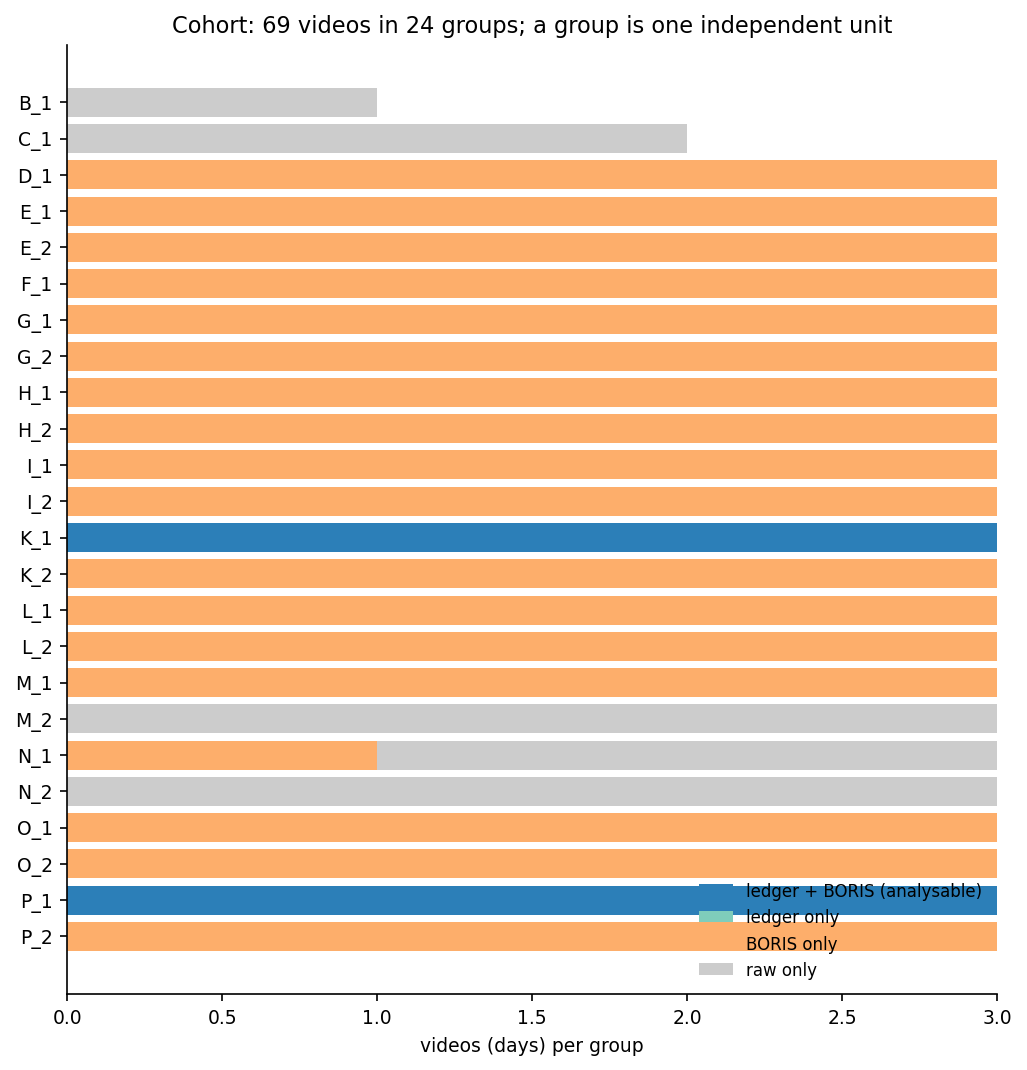

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S0_01_cohort_videos_per_group.png


In [3]:
colors = {"ledger + BORIS (analysable)": "#2c7fb8", "ledger only": "#7fcdbb", "BORIS only": "#fdae6b", "raw only": "#cccccc"}
by_group = cohort.groupby(["group", "status"]).size().unstack(fill_value=0)
by_group = by_group.reindex(columns=list(colors), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 0.28 * len(by_group) + 1.5))
left = np.zeros(len(by_group))
for status, c in colors.items():
    ax.barh(by_group.index, by_group[status], left=left, color=c, label=status)
    left += by_group[status].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("videos (days) per group")
ax.set_title(f"Cohort: {len(cohort)} videos in {len(by_group)} groups; a group is one independent unit")
ax.legend(frameon=False, fontsize=8, loc="lower right")
show(fig, 0, 1, "cohort_videos_per_group")

group split                       rule          created
  P_1  test sha256 rank, seed 20261106 2026-11-06 12:25
  K_1   dev sha256 rank, seed 20261106 2026-11-06 12:25

DEV groups: 1   TEST groups: 1


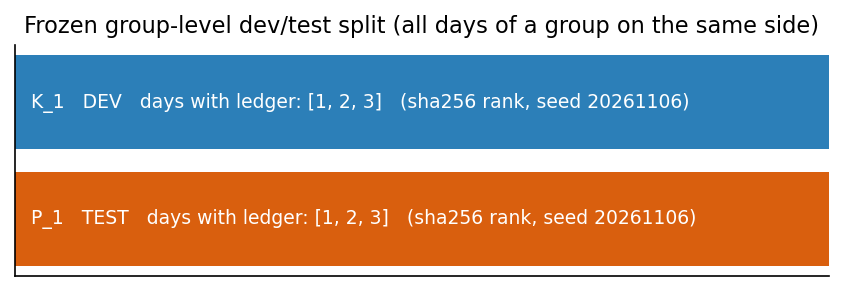

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S0_02_dev_test_split.png


In [4]:
groups_ready = sorted({M.parse_experiment(e)[0] for e in ledger})
split = M.freeze_split(groups_ready)
print(split.to_string(index=False))
n_dev, n_test = (split["split"] == "dev").sum(), (split["split"] == "test").sum()
print(f"\nDEV groups: {n_dev}   TEST groups: {n_test}")
print("WARNING: only", len(split), "groups have an identity ledger, so this split is 1 vs 1."
      " Every number from dev is n_groups = %d. New groups are appended to split.csv, existing rows never change." % n_dev)

fig, ax = plt.subplots(figsize=(7, 1.0 + 0.5 * len(split)))
for i, r in enumerate(split.itertuples()):
    days = sorted(cohort.loc[(cohort["group"] == r.group) & cohort["has_ledger"], "day"])
    ax.barh(i, 1, color="#2c7fb8" if r.split == "dev" else "#d95f0e")
    ax.text(0.02, i, f"{r.group}   {r.split.upper()}   days with ledger: {days}   ({r.rule})", va="center", color="white", fontsize=9)
ax.set_yticks([]); ax.set_xticks([]); ax.set_xlim(0, 1)
ax.set_title("Frozen group-level dev/test split (all days of a group on the same side)")
show(fig, 0, 2, "dev_test_split")

## 每个视频的记录

帧率、帧数、分析可用帧比例、每条鱼的体长。体长取 嘴–尾 三维距离的中位数（3 点骨架，**不含尾鳍**，所以比全长短）；头–胸鳍和胸鳍–尾也记下，阶段 1 要用。

标定：录像元数据里**没有每个视频的标定记录**，所以“标定有没有变过”目前**无法从数据确认**。
阶段 1 因此按 (视频, 个体) 各算一个中位数，这是最严格的做法，等于假设每个视频是独立的标定会话。
测试组只记录录像元数据，不读轨迹，所以体长列为空。

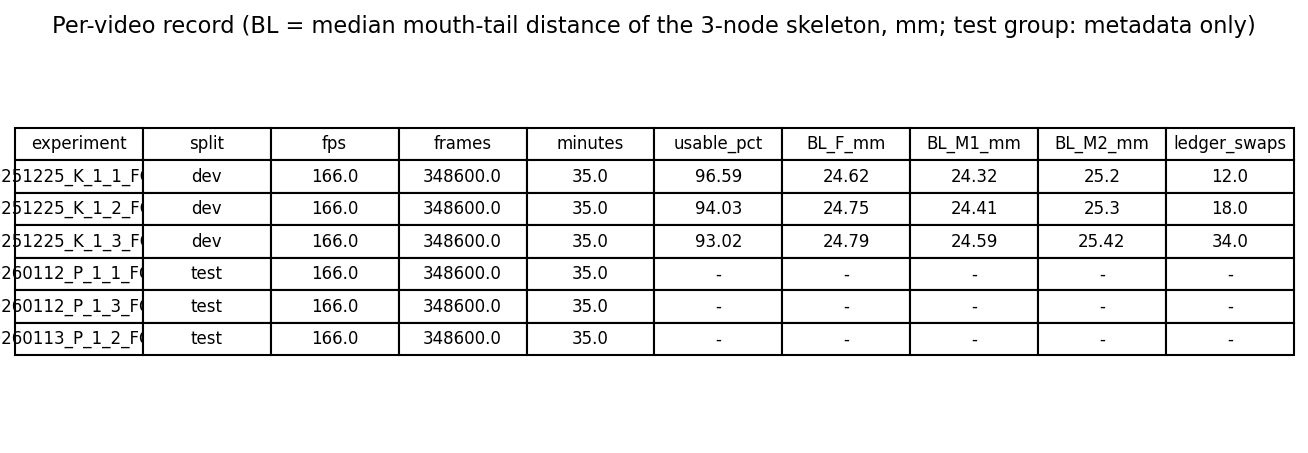

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S0_03_video_records.png


,experiment,split,fps,frames,minutes,usable_pct,BL_F_mm,BL_M1_mm,BL_M2_mm,ledger_swaps
0,20251225_K_1_1_FCMC,dev,166.0,348600.0,35.0,96.59,24.62,24.32,25.20,12.0
1,20251225_K_1_2_FCMC,dev,166.0,348600.0,35.0,94.03,24.75,24.41,25.30,18.0
2,20251225_K_1_3_FCMC,dev,166.0,348600.0,35.0,93.02,24.79,24.59,25.42,34.0
3,20260112_P_1_1_FCMC,test,166.0,348600.0,35.0,NaN,NaN,NaN,NaN,NaN
4,20260112_P_1_3_FCMC,test,166.0,348600.0,35.0,NaN,NaN,NaN,NaN,NaN
5,20260113_P_1_2_FCMC,test,166.0,348600.0,35.0,NaN,NaN,NaN,NaN,NaN


In [5]:
rec = []
for e in cohort.loc[cohort["has_ledger"], "experiment"]:
    row = cohort.set_index("experiment").loc[e, ["group", "day", "fps", "frames", "minutes"]].to_dict()
    row["experiment"] = e
    row["split"] = M.split_of(e)
    if row["split"] == "dev":
        tr = M.load_trial(e)
        L = M.skeleton_lengths(tr["named"])
        row["usable_pct"] = round(100 * tr["usable_frac"], 2)
        for k, tag in (("head_tail", "BL"), ("head_pec", "head_pec"), ("pec_tail", "pec_tail")):
            med = np.nanmedian(L[k], axis=0)
            for name, v in zip(M.NAMES, med):
                row[f"{tag}_{name}_mm"] = round(float(v), 2)
        row["ledger_swaps"] = len(tr["swap_frames"])
    rec.append(row)
records = pd.DataFrame(rec)
records["calibration_record"] = "none per video"
records.to_csv(OUT / "S0_video_records.csv", index=False)

show_cols = ["experiment", "split", "fps", "frames", "minutes", "usable_pct", "BL_F_mm", "BL_M1_mm", "BL_M2_mm", "ledger_swaps"]
tbl = records[show_cols].copy()
tbl["minutes"] = tbl["minutes"].round(1)
fig, ax = plt.subplots(figsize=(11, 0.4 * len(tbl) + 1))
ax.axis("off")
t = ax.table(cellText=tbl.fillna("-").astype(str).values, colLabels=show_cols, loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(8); t.scale(1, 1.3)
ax.set_title("Per-video record (BL = median mouth-tail distance of the 3-node skeleton, mm; test group: metadata only)")
show(fig, 0, 3, "video_records")
records[show_cols]

## 身份：错配是不是集中在近距离帧

账本里的 swap 是人工确认的身份交换。对每个 swap，取其前后各 0.5 s 内**最近一对鱼**的质心距离（体长为单位），
与所有帧的同一统计量比较。如果错配集中在近距离帧，近距离互动帧的身份可靠性就要单独交代（阶段 11）。
只用开发组。这一步用的是身份账本，不是行为标记。

         experiment  swaps  swaps_with_distance
20251225_K_1_1_FCMC     12                   12
20251225_K_1_2_FCMC     18                   18
20251225_K_1_3_FCMC     34                   34
nearest-pair distance (BL): at swaps median 0.31 (n=64), random windows median 0.90, all frames median 1.33


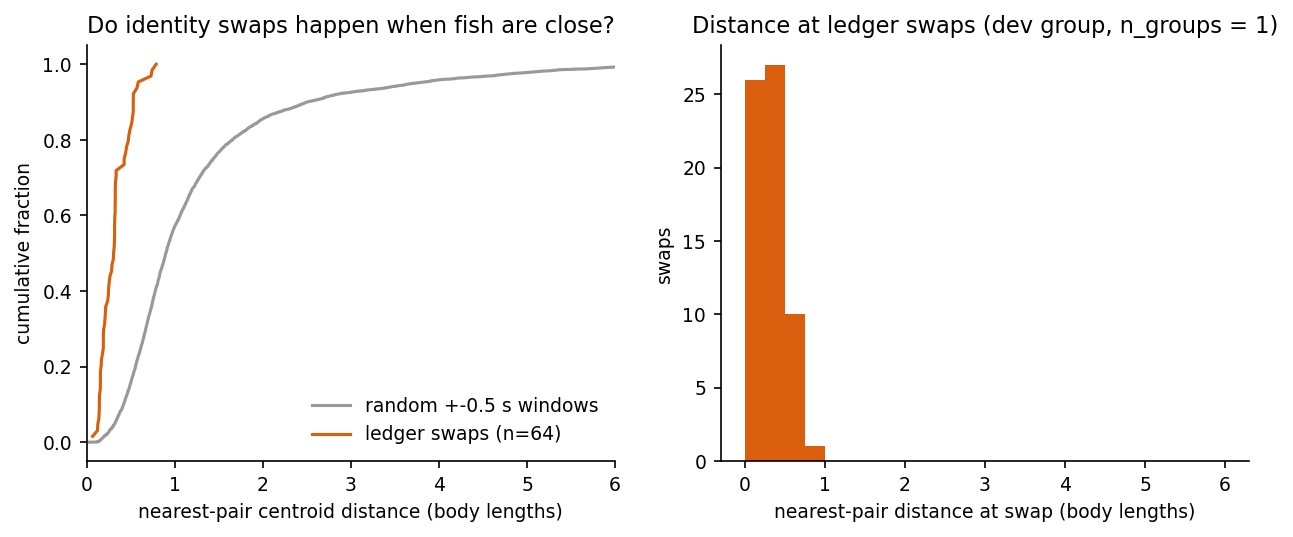

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S0_04_swap_distance_vs_baseline.png


In [6]:
DEV = M.trials("dev")
HALF = 83
rng = np.random.default_rng(0)
dist_all, dist_swap, base, per_trial = [], [], [], []
tracks_cache = {}
for e in DEV:
    tr = M.load_trial(e, keep_tracks=True)
    cen = np.nanmean(tr["tracks"], axis=2)               # (T, 3 tracks, 3), mm, uncorrected track identities
    bl = np.nanmedian(M.skeleton_lengths(tr["named"])["head_tail"])
    pair_d = np.stack([np.linalg.norm(cen[:, a] - cen[:, b], axis=-1) for a, b in ((0, 1), (0, 2), (1, 2))], 1)
    dmin = np.nanmin(np.where(np.isfinite(pair_d), pair_d, np.inf), axis=1) / bl
    dmin[~np.isfinite(dmin)] = np.nan
    ok = ~tr["blocked"]
    fr0 = tr["frames"][0]
    window_min = lambda i: np.nanmin(dmin[max(i - HALF, 0): i + HALF + 1]) if np.isfinite(dmin[max(i - HALF, 0): i + HALF + 1]).any() else np.nan
    sw = [window_min(int(f - fr0)) for f in tr["swap_frames"]]
    dist_swap.append(np.asarray([v for v in sw if np.isfinite(v)]))
    base.extend(v for v in (window_min(int(i)) for i in rng.choice(np.flatnonzero(ok), 2000, replace=False)) if np.isfinite(v))
    dist_all.append(dmin[ok])
    per_trial.append({"experiment": e, "swaps": len(tr["swap_frames"]), "swaps_with_distance": len(dist_swap[-1])})
    tracks_cache[e] = (cen, tr["swap_frames"], tr["fps"], fr0, ok)
dist_all = np.concatenate(dist_all); dist_swap = np.concatenate(dist_swap); base = np.asarray(base)
print(pd.DataFrame(per_trial).to_string(index=False))
print(f"nearest-pair distance (BL): at swaps median {np.median(dist_swap):.2f} (n={len(dist_swap)}), "
      f"random windows median {np.median(base):.2f}, all frames median {np.nanmedian(dist_all):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for v, lab, c in ((base, "random +-0.5 s windows", "#999999"), (dist_swap, f"ledger swaps (n={len(dist_swap)})", "#d95f0e")):
    x = np.sort(v)
    ax[0].plot(x, np.arange(1, len(x) + 1) / len(x), label=lab, color=c)
ax[0].set_xlim(0, 6); ax[0].set_xlabel("nearest-pair centroid distance (body lengths)"); ax[0].set_ylabel("cumulative fraction")
ax[0].legend(frameon=False); ax[0].set_title("Do identity swaps happen when fish are close?")
ax[1].hist(dist_swap, bins=np.linspace(0, 6, 25), color="#d95f0e")
ax[1].set_xlabel("nearest-pair distance at swap (body lengths)"); ax[1].set_ylabel("swaps")
ax[1].set_title("Distance at ledger swaps (dev group, n_groups = 1)")
show(fig, 0, 4, "swap_distance_vs_baseline")

## 用加速度阈值找疑似身份交换

论文：质心加速度超过 3.3 的帧，前后各删 6 帧。**论文正文没写单位**，所以不借用 3.3。这里取原始轨迹（未用账本纠正）质心加速度的 99.9 百分位作阈值，
看这样标出的帧能抓到多少账本里的 swap（±0.5 s 内有标记算命中），并与随机位置的命中率对比。
这只是自动定位工具，不在这里删帧。

threshold = 237187 mm/s^2 (99.9% quantile of dev track centroids)


         experiment  swaps  swap_hit_rate  chance_rate  frames_flagged  frames_deleted_pm6
20251225_K_1_1_FCMC     12          0.833        0.128            1600                9529
20251225_K_1_2_FCMC     18          0.833        0.143            1439               10077
20251225_K_1_3_FCMC     34          0.912        0.158            2092               13055


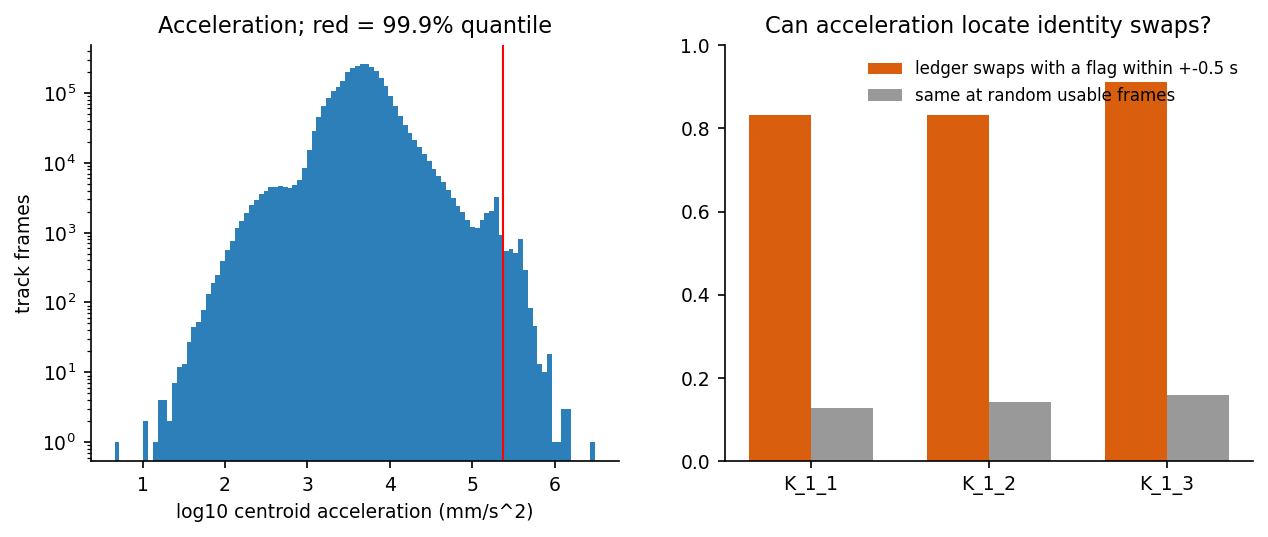

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S0_05_acceleration_jump_vs_swaps.png


In [7]:
Q = 0.999
acc_all, flags = [], {}
for e in DEV:
    cen, swaps, fps, fr0, ok = tracks_cache[e]
    a = np.linalg.norm(cen[2:] - 2 * cen[1:-1] + cen[:-2], axis=-1) * fps ** 2      # mm/s^2, (T-2, 3 tracks)
    a = np.vstack([np.full((1, 3), np.nan), a, np.full((1, 3), np.nan)])
    a[~ok] = np.nan
    acc_all.append(a[np.isfinite(a)])
acc_all = np.concatenate(acc_all)
thr = float(np.quantile(acc_all, Q))
print(f"threshold = {thr:.0f} mm/s^2 ({Q:.1%} quantile of dev track centroids)")
hit_rows = []
for e in DEV:
    cen, swaps, fps, fr0, ok = tracks_cache[e]
    a = np.linalg.norm(cen[2:] - 2 * cen[1:-1] + cen[:-2], axis=-1) * fps ** 2
    a = np.vstack([np.full((1, 3), np.nan), a, np.full((1, 3), np.nan)])
    flag = np.nan_to_num(a, nan=0) > thr
    anyflag = flag.any(1)
    near = np.convolve(anyflag, np.ones(2 * HALF + 1), mode="same") > 0
    sw_idx = np.asarray([int(f - fr0) for f in swaps], int)
    hit = near[sw_idx].mean() if len(sw_idx) else np.nan
    chance = near[np.flatnonzero(ok)].mean()
    del_frames = np.convolve(anyflag, np.ones(13), mode="same") > 0
    hit_rows.append({"experiment": e, "swaps": len(sw_idx), "swap_hit_rate": hit, "chance_rate": chance,
                     "frames_flagged": int(anyflag.sum()), "frames_deleted_pm6": int(del_frames.sum())})
hits = pd.DataFrame(hit_rows)
hits.to_csv(OUT / "S0_acceleration_swap_detection.csv", index=False)
print(hits.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(np.log10(acc_all[acc_all > 0]), bins=100, color="#2c7fb8")
ax[0].axvline(np.log10(thr), color="r", lw=1); ax[0].set_yscale("log")
ax[0].set_xlabel("log10 centroid acceleration (mm/s^2)"); ax[0].set_ylabel("track frames")
ax[0].set_title(f"Acceleration; red = {Q:.1%} quantile")
w = 0.35; x = np.arange(len(hits))
ax[1].bar(x - w / 2, hits["swap_hit_rate"], w, label="ledger swaps with a flag within +-0.5 s", color="#d95f0e")
ax[1].bar(x + w / 2, hits["chance_rate"], w, label="same at random usable frames", color="#999999")
ax[1].set_xticks(x); ax[1].set_xticklabels([e[9:-5] for e in hits["experiment"]]); ax[1].set_ylim(0, 1)
ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("Can acceleration locate identity swaps?")
show(fig, 0, 5, "acceleration_jump_vs_swaps")

In [8]:
M.update_params("stage0", {
    "split_seed": M.SPLIT_SEED, "dev_groups": split.loc[split["split"] == "dev", "group"].tolist(),
    "test_groups": split.loc[split["split"] == "test", "group"].tolist(), "n_groups_dev": int(n_dev),
    "acceleration_quantile": Q, "acceleration_threshold_mm_s2": thr,
    "n_swaps": int(len(dist_swap)), "swap_median_nearest_pair_BL": float(np.median(dist_swap)),
    "random_window_median_nearest_pair_BL": float(np.median(base)),
    "accel_swap_hit_rate": float(hits["swap_hit_rate"].mean()), "accel_chance_rate": float(hits["chance_rate"].mean()),
    "calibration": "no per-video record; thresholds are per (video, fish)"})
print(M.load_params()["stage0"])

{'split_seed': 20261106, 'dev_groups': ['K_1'], 'test_groups': ['P_1'], 'n_groups_dev': 1, 'acceleration_quantile': 0.999, 'acceleration_threshold_mm_s2': 237186.70347709933, 'n_swaps': 64, 'swap_median_nearest_pair_BL': 0.30888883375700166, 'random_window_median_nearest_pair_BL': 0.8999210723674602, 'accel_swap_hit_rate': 0.8594771241830066, 'accel_chance_rate': 0.14311069403455015, 'calibration': 'no per-video record; thresholds are per (video, fish)'}
